#Aqui estamos cargando la data fisica

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path

DATASETS = {
    "series": "app_data_series.csv",
    "monthly": "app_data.csv",
    "yearly": "app_data_yearly.csv",
    "annual_normal": "app_data_annual_normal.csv"
}

data = {}

for name, filename in DATASETS.items():
    path = Path("/content") / filename

    if not path.exists():
        raise FileNotFoundError(
            f"Falta subir el archivo: {filename}"
        )

    df = pd.read_csv(path)
    df.columns = df.columns.str.strip()
    data[name] = df

    print(f"\n✅ {filename}")
    print(f"   Rows: {len(df):,}")
    print(f"   Columns: {len(df.columns)}")
    print(f"   Unique points: {df['point_id'].nunique()}")

print("\n===== DATASETS LOADED =====")



✅ app_data_series.csv
   Rows: 13,824
   Columns: 22
   Unique points: 192

✅ app_data.csv
   Rows: 2,304
   Columns: 21
   Unique points: 192

✅ app_data_yearly.csv
   Rows: 1,152
   Columns: 14
   Unique points: 192

✅ app_data_annual_normal.csv
   Rows: 192
   Columns: 13
   Unique points: 192

===== DATASETS LOADED =====


#Cargamos ECOCROP

In [ ]:

# FIELD SHIFT — ECOCROP DATA LOADING

import pandas as pd

ecocrop_url = (
    "https://digital-atlas.s3.amazonaws.com/"
    "cdh/data/ecocrop/ecocrop.parquet"
)

ecocrop = pd.read_parquet(ecocrop_url)

print("✅ ECOCROP loaded successfully!")
print(f"Total records: {len(ecocrop):,}")
print(f"Total columns: {len(ecocrop.columns)}")

display(ecocrop.head(3))


✅ ECOCROP loaded successfully!
Total records: 2,568
Total columns: 55


,ecoportcode,scientificname,auth,famname,syno,comname,lifo,habi,lispa,phys,...,ktmpr,ktmp,photo,cliz,abitol,abisus,intri,prosy,gmin,gmax
0,289,Abelmoschus esculentus,(L.) Moench,Magnoliopsida:Dilleniidae:Malvales:Malvaceae,[Hibiscus esculentus L.],"[abelmoskus, america-neri, bakhua mun, bamia, ...",[herb],[erect],[annual],[single stem],...,<NA>,<NA>,[short day (<12 hours)],"[tropical wet & dry (Aw), tropical wet (Ar), s...",None,None,None,None,50,180
1,290,Abelmoschus manihot,(L.) Medic.,Magnoliopsida:Dilleniidae:Malvales:Malvaceae,"[Hibiscus manihot L. (1753), Abelmoschus manih...","[neka (Simbo), bele (Fiji), pele (Tonga, Tuval...",[shrub],[erect],"[annual, perennial]",None,...,<NA>,<NA>,[long day (>14 hours)],"[tropical wet & dry (Aw), tropical wet (Ar)]",None,None,None,None,365,365
2,291,Abelmoschus moschatus,Medic.,Magnoliopsida:Dilleniidae:Malvales:Malvaceae,[Hibiscus abelmoschus L. (1753).],"[abelmosk, musk mallow, mushkdan, muskdana, ka...","[herb, sub-shrub]",[prostrate/procumbent/semi-erect],"[annual, biennial, perennial]","[deciduous, multi stem]",...,<NA>,<NA>,None,[tropical wet & dry (Aw)],None,None,[can become a weed],None,0,0


#Extraer nuestros cuatro cultivos

In [ ]:

# FIELD SHIFT — CROP SELECTION

target_crops = {
    364: "Cebolla",
    871: "Zanahoria",
    1265: "Camote",
    1971: "Papa"
}

crop_columns = [
    "ecoportcode",
    "scientificname",
    "topmn", "topmx",
    "tmin", "tmax",
    "ropmn", "ropmx",
    "rmin", "rmax",
    "gmin", "gmax",
    "dra", "drar"
]

crop_requirements = ecocrop[
    ecocrop["ecoportcode"].isin(target_crops)
][crop_columns].copy()

crop_requirements.insert(
    0,
    "crop",
    crop_requirements["ecoportcode"].map(target_crops)
)

crop_requirements = crop_requirements.sort_values(
    "ecoportcode"
).reset_index(drop=True)

print("✅ Selected crops:", len(crop_requirements))

display(crop_requirements)


✅ Selected crops: 4


,crop,ecoportcode,scientificname,topmn,topmx,tmin,tmax,ropmn,ropmx,rmin,rmax,gmin,gmax,dra,drar
0,Cebolla,364,Allium cepa,12,25,4,30,350,600,300,2800,85,175,[well (dry spells)],[well (dry spells)]
1,Zanahoria,871,Daucus carota,15,24,3,30,600,1200,400,4000,40,150,[well (dry spells)],[well (dry spells)]
2,Camote,1265,Ipomoea batatas,18,28,10,38,750,2000,350,5000,80,170,None,None
3,Papa,1971,Solanum tuberosum,15,25,7,30,500,800,250,2000,90,160,[well (dry spells)],"[well (dry spells), excessive (dry/moderately ..."


#Validación rápida de ECOCROP

Confirmemos que tenemos los cuatro cultivos, sin duplicados ni valores faltantes en los campos numéricos que utilizaremos.

In [ ]:

# FIELD SHIFT — ECOCROP VALIDATION

numeric_fields = [
    "topmn", "topmx",
    "tmin", "tmax",
    "ropmn", "ropmx",
    "rmin", "rmax",
    "gmin", "gmax"
]

print("========== ECOCROP VALIDATION ==========")

print("Crops found:", len(crop_requirements))

print(
    "Missing crops:",
    set(target_crops) -
    set(crop_requirements["ecoportcode"])
)

print(
    "Duplicate crop IDs:",
    crop_requirements["ecoportcode"].duplicated().sum()
)

print("\nMissing numeric values:")
display(crop_requirements[numeric_fields].isna().sum())

assert len(crop_requirements) == 4, \
    "Expected exactly 4 crops"

assert not crop_requirements[numeric_fields].isna().any().any(), \
    "Missing numeric crop requirements"

print("\n✅ ECOCROP VALIDATION PASSED")


========== ECOCROP VALIDATION ==========
Crops found: 4
Missing crops: set()
Duplicate crop IDs: 0

Missing numeric values:


,0
topmn,0
topmx,0
tmin,0
tmax,0
ropmn,0
ropmx,0
rmin,0
rmax,0
gmin,0
gmax,0



✅ ECOCROP VALIDATION PASSED


#NASA DATA

data["series"] — histórico mensual 2020–2025.



data["monthly"] — los 12 meses típicos por punto.



data["yearly"] — estadísticas de cada año.



data["annual_normal"] — clima anual típico.



crop_requirements — nuestros cuatro cultivos ECOCROP.

#Validación de integridad de los datasets NASA

Objetivo: comprobar que las cuatro tablas de ASH representan los mismos 192 puntos y que sus registros no tienen duplicados ni períodos faltantes.

Esto es importante porque, cuando SEBAS seleccione un point_id en Leaflet, todas nuestras fuentes deben devolver información consistente.

In [ ]:

# FIELD SHIFT — NASA DATA INTEGRITY VALIDATION

print("========== NASA DATA INTEGRITY ==========")

expected_rows = {
    "series": 192 * 72,
    "monthly": 192 * 12,
    "yearly": 192 * 6,
    "annual_normal": 192
}

keys = {
    "series": ["point_id", "year", "month"],
    "monthly": ["point_id", "month"],
    "yearly": ["point_id", "year"],
    "annual_normal": ["point_id"]
}

reference_points = set(
    data["series"]["point_id"].dropna()
)

results = []

for name, df in data.items():

    unique_points = df["point_id"].nunique()

    duplicate_keys = df.duplicated(
        subset=keys[name]
    ).sum()

    same_points = (
        set(df["point_id"].dropna()) ==
        reference_points
    )

    results.append({
        "dataset": name,
        "rows": len(df),
        "expected_rows": expected_rows[name],
        "unique_points": unique_points,
        "duplicate_keys": duplicate_keys,
        "same_points": same_points,
        "complete_row_count": (
            len(df) == expected_rows[name]
        )
    })

audit = pd.DataFrame(results)

display(audit)

print("\n========== TEMPORAL COVERAGE ==========")

series = data["series"]

print("Years:", sorted(series["year"].unique()))
print("Months:", sorted(series["month"].unique()))

coverage = (
    series.groupby("point_id")
    .agg(
        records=("month", "size"),
        unique_months=("month", "nunique"),
        unique_years=("year", "nunique")
    )
)

print("\nRecords per point:")
display(coverage.describe())

print("\nPoints without 72 records:")
display(
    coverage[coverage["records"] != 72]
)

print("\n========== RESULT ==========")

if (
    audit["complete_row_count"].all()
    and (audit["duplicate_keys"] == 0).all()
    and audit["same_points"].all()
    and (coverage["records"] == 72).all()
    and (coverage["unique_years"] == 6).all()
):
    print("✅ NASA STRUCTURAL VALIDATION PASSED")
else:
    print("⚠️ NASA STRUCTURAL VALIDATION NEEDS REVIEW")


========== NASA DATA INTEGRITY ==========


,dataset,rows,expected_rows,unique_points,duplicate_keys,same_points,complete_row_count
0,series,13824,13824,192,0,True,True
1,monthly,2304,2304,192,0,True,True
2,yearly,1152,1152,192,0,True,True
3,annual_normal,192,192,192,0,True,True



========== TEMPORAL COVERAGE ==========
Years: [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Months: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]

Records per point:


,records,unique_months,unique_years
count,192.0,192.0,192.0
mean,72.0,12.0,6.0
std,0.0,0.0,0.0
min,72.0,12.0,6.0
25%,72.0,12.0,6.0
50%,72.0,12.0,6.0
75%,72.0,12.0,6.0
max,72.0,12.0,6.0



Points without 72 records:


,records,unique_months,unique_years
point_id,,,



========== RESULT ==========
✅ NASA STRUCTURAL VALIDATION PASSED


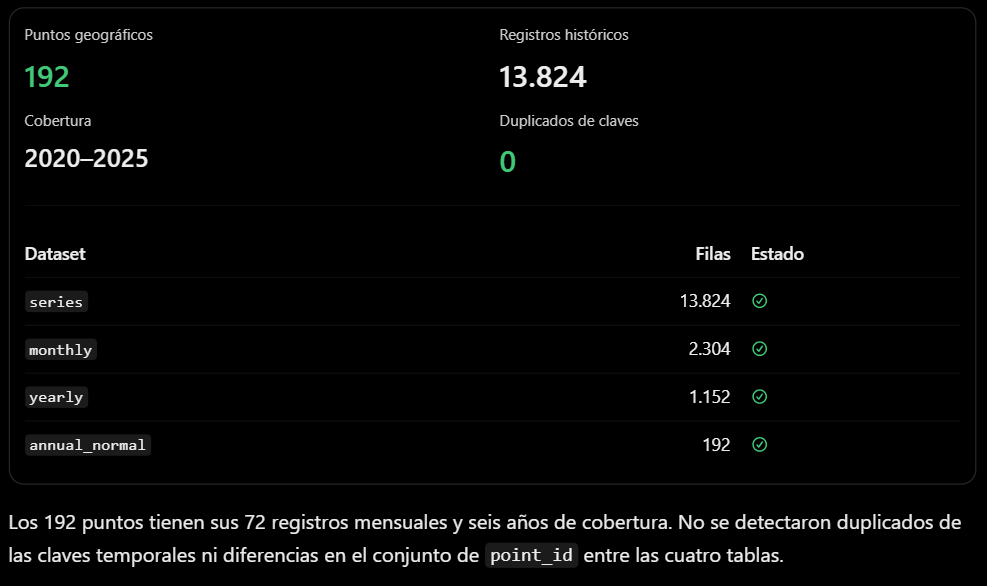

#Validación cruzada entre datasets NASA

Ahora vamos a comprobar algo más importante: que los valores del dataset mensual típico realmente se obtengan a partir del histórico.

Para no perder tiempo, probaremos los 192 puntos y los 12 meses de una vez, comparando temperatura, lluvia, ETo, balance e indicador de humedad.

In [ ]:

# FIELD SHIFT — NASA CROSS-DATASET VALIDATION

series = data["series"].copy()
monthly = data["monthly"].copy()

variables = [
    "rain_mm",
    "tmax_c",
    "tmin_c",
    "eto_mm",
    "balance_mm",
    "soil_wetness"
]

# Recalculate historical monthly averages
recalculated = (
    series.groupby(
        ["point_id", "month"],
        as_index=False
    )[variables]
    .mean()
)

# Compare against ASH's processed monthly dataset
comparison = recalculated.merge(
    monthly[
        ["point_id", "month"] + variables
    ],
    on=["point_id", "month"],
    suffixes=("_calculated", "_ash"),
    validate="one_to_one"
)

results = []

for variable in variables:
    calculated = comparison[f"{variable}_calculated"]
    ash = comparison[f"{variable}_ash"]

    difference = (calculated - ash).abs()

    results.append({
        "variable": variable,
        "max_difference": difference.max(),
        "avg_difference": difference.mean(),
        "mismatches": (difference > 0.05).sum()
    })

validation = pd.DataFrame(results)

print("========== MONTHLY VALIDATION ==========")
print("Rows compared:", len(comparison))

display(validation)

if (
    len(comparison) == len(monthly)
    and (validation["mismatches"] == 0).all()
):
    print("✅ MONTHLY AGGREGATIONS VALIDATED")
else:
    print("⚠️ AGGREGATION DIFFERENCES DETECTED")


========== MONTHLY VALIDATION ==========
Rows compared: 2304


,variable,max_difference,avg_difference,mismatches
0,rain_mm,0.005000,0.002274,0
1,tmax_c,0.008333,0.003151,0
2,tmin_c,0.008333,0.003676,0
3,eto_mm,0.008333,0.002585,0
4,balance_mm,0.006667,0.002573,0
5,soil_wetness,0.005000,0.002031,0


✅ MONTHLY AGGREGATIONS VALIDATED


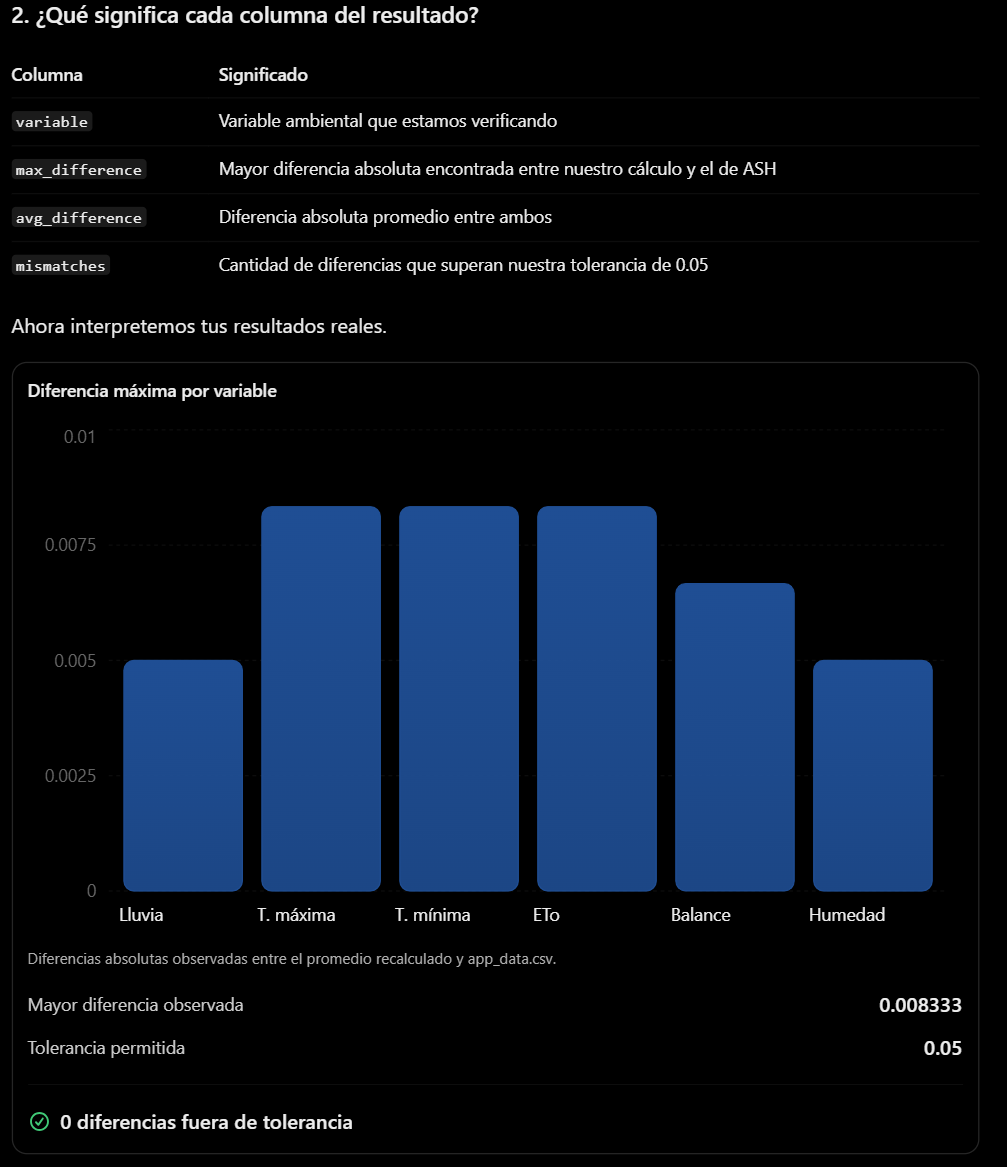

#VALIDACIÓN ANUAL DE ASH.

Ahora vamos a comprobar que los dos archivos anuales coincidan matemáticamente con los datos históricos originales.

No vamos a modificar ningún dataset. Solo vamos a recalcular y comparar.
1. ¿Qué vamos a validar?
Variable	series → yearly	yearly → annual_normal
Lluvia	Suma de 12 meses	Promedio de 6 totales anuales
ETo	Suma de 12 meses	Promedio de 6 totales anuales
Balance hídrico	Suma de 12 meses	Promedio de 6 totales anuales
Temperaturas	Promedio de 12 meses	Promedio de 6 años
Humedad	Promedio de 12 meses	Promedio de 6 años

Estas son las operaciones que ASH documentó en su README.

In [ ]:

# FIELD SHIFT — YEARLY AGGREGATION VALIDATION

series = data["series"].copy()
yearly = data["yearly"].copy()

sum_columns = [
    "rain_mm",
    "eto_mm",
    "balance_mm"
]

mean_columns = [
    "tmax_c",
    "tmin_c",
    "soil_wetness"
]

# Recalculate yearly values from historical series
recalculated_yearly = (
    series.groupby(
        ["point_id", "year"],
        as_index=False
    )
    .agg({
        **{col: "sum" for col in sum_columns},
        **{col: "mean" for col in mean_columns}
    })
)

# Match recalculated values with ASH's yearly data
comparison_yearly = recalculated_yearly.merge(
    yearly[
        ["point_id", "year"]
        + sum_columns + mean_columns
    ],
    on=["point_id", "year"],
    suffixes=("_calculated", "_ash"),
    validate="one_to_one"
)

results = []

for variable in sum_columns + mean_columns:
    diff = (
        comparison_yearly[f"{variable}_calculated"]
        - comparison_yearly[f"{variable}_ash"]
    ).abs()

    results.append({
        "variable": variable,
        "max_difference": diff.max(),
        "avg_difference": diff.mean(),
        "mismatches": (diff > 0.10).sum()
    })

yearly_validation = pd.DataFrame(results)

print("========== YEARLY VALIDATION ==========")
print("Rows compared:", len(comparison_yearly))

display(yearly_validation)

if (
    len(comparison_yearly) == len(yearly)
    and (yearly_validation["mismatches"] == 0).all()
):
    print("✅ YEARLY AGGREGATIONS VALIDATED")
else:
    print("⚠️ YEARLY AGGREGATIONS NEED REVIEW")


========== YEARLY VALIDATION ==========
Rows compared: 1152


,variable,max_difference,avg_difference,mismatches
0,rain_mm,0.000000,0.000000,0
1,eto_mm,0.030000,0.007908,0
2,balance_mm,0.030000,0.007908,0
3,tmax_c,0.009167,0.003071,0
4,tmin_c,0.009167,0.003555,0
5,soil_wetness,0.005000,0.002378,0


✅ YEARLY AGGREGATIONS VALIDATED


#Validar app_data_annual_normal.csv

In [ ]:

# FIELD SHIFT — ANNUAL NORMAL VALIDATION

annual_normal = data["annual_normal"].copy()

variables = [
    "rain_mm",
    "tmax_c",
    "tmin_c",
    "eto_mm",
    "balance_mm",
    "soil_wetness"
]

# Average the six yearly observations per point
recalculated_normal = (
    yearly.groupby(
        "point_id",
        as_index=False
    )[variables]
    .mean()
)

comparison_normal = recalculated_normal.merge(
    annual_normal[
        ["point_id"] + variables
    ],
    on="point_id",
    suffixes=("_calculated", "_ash"),
    validate="one_to_one"
)

results = []

for variable in variables:
    diff = (
        comparison_normal[f"{variable}_calculated"]
        - comparison_normal[f"{variable}_ash"]
    ).abs()

    results.append({
        "variable": variable,
        "max_difference": diff.max(),
        "avg_difference": diff.mean(),
        "mismatches": (diff > 0.10).sum()
    })

normal_validation = pd.DataFrame(results)

print("========== ANNUAL NORMAL VALIDATION ==========")
print("Rows compared:", len(comparison_normal))

display(normal_validation)

if (
    len(comparison_normal) == len(annual_normal)
    and (normal_validation["mismatches"] == 0).all()
):
    print("✅ ANNUAL NORMAL VALIDATED")
else:
    print("⚠️ ANNUAL NORMAL NEEDS REVIEW")


========== ANNUAL NORMAL VALIDATION ==========
Rows compared: 192


,variable,max_difference,avg_difference,mismatches
0,rain_mm,0.003333,0.001875,0
1,tmax_c,0.005000,0.002526,0
2,tmin_c,0.005000,0.002752,0
3,eto_mm,0.005000,0.002500,0
4,balance_mm,0.005000,0.002500,0
5,soil_wetness,0.005000,0.000521,0


✅ ANNUAL NORMAL VALIDATED


#Nuestro primer matching real NASA × ECOCROP

Ahora sí vamos a probar el motor con un punto geográfico y los cuatro cultivos.

Por ahora vamos a evaluar únicamente temperatura. Después incorporamos los otros indicadores y calculamos las ventanas completas.

Objetivo: saber qué tan compatibles son las temperaturas históricas típicas de cada mes con los requerimientos de papa, cebolla, zanahoria y camote.

## Preparar datos del punto

In [ ]:

# FIELD SHIFT — FIRST NASA × ECOCROP MATCHING

POINT_ID = 4

point_data = (
    data["monthly"][
        data["monthly"]["point_id"] == POINT_ID
    ]
    .sort_values("month")
    .copy()
)

assert len(point_data) == 12, (
    "Expected 12 monthly records for this point"
)

# Use ASH's temperature methodology
if "tmean_c" not in point_data.columns:
    point_data["tmean_c"] = (
        point_data["tmax_c"] +
        point_data["tmin_c"]
    ) / 2

print(f"========== POINT {POINT_ID} ==========")

display(
    point_data[
        [
            "point_id",
            "month",
            "tmean_c",
            "rain_mm",
            "eto_mm",
            "soil_wetness",
            "balance_mm"
        ]
    ]
)


========== POINT 4 ==========


,point_id,month,tmean_c,rain_mm,eto_mm,soil_wetness,balance_mm
36,4,1,17.620,84.51,82.40,0.86,2.11
37,4,2,18.215,60.52,91.08,0.74,-30.56
38,4,3,18.995,116.92,115.32,0.68,1.61
39,4,4,19.135,242.12,106.20,0.71,135.92
40,4,5,19.010,340.42,93.74,0.81,246.67
41,4,6,18.240,434.60,81.76,0.94,352.84
42,4,7,18.330,366.73,88.54,0.97,278.20
43,4,8,18.285,289.13,90.85,0.97,198.28
44,4,9,18.335,334.60,86.96,0.98,247.64
45,4,10,17.945,384.61,78.54,0.99,306.07


##Comparar los cuatro cultivos

In [ ]:

# FIELD SHIFT — TEMPERATURE SUITABILITY

def evaluate_temperature(value, crop):
    if pd.isna(value):
        return "unknown"

    if crop["topmn"] <= value <= crop["topmx"]:
        return "favorable"

    if crop["tmin"] <= value <= crop["tmax"]:
        return "caution"

    return "unfavorable"


results = []

for _, crop in crop_requirements.iterrows():
    for _, month in point_data.iterrows():

        status = evaluate_temperature(
            month["tmean_c"],
            crop
        )

        results.append({
            "point_id": POINT_ID,
            "crop": crop["crop"],
            "crop_id": int(crop["ecoportcode"]),
            "month": int(month["month"]),
            "temperature_c": round(
                float(month["tmean_c"]), 2
            ),
            "status": status
        })

temperature_matching = pd.DataFrame(results)

display(
    temperature_matching.pivot(
        index="month",
        columns="crop",
        values="status"
    )
)


crop,Camote,Cebolla,Papa,Zanahoria
month,,,,
1,caution,favorable,favorable,favorable
2,favorable,favorable,favorable,favorable
3,favorable,favorable,favorable,favorable
4,favorable,favorable,favorable,favorable
5,favorable,favorable,favorable,favorable
6,favorable,favorable,favorable,favorable
7,favorable,favorable,favorable,favorable
8,favorable,favorable,favorable,favorable
9,favorable,favorable,favorable,favorable


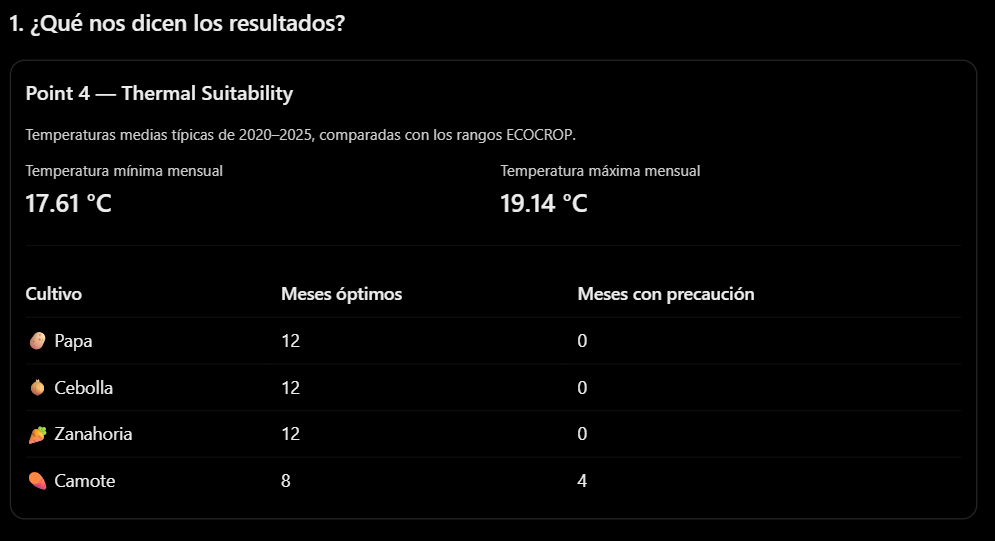

En el punto 4, papa, cebolla y zanahoria tienen temperaturas medias favorables durante todo el año.

El camote presenta condiciones térmicas óptimas de febrero a septiembre, mientras que enero y octubre–diciembre quedan dentro de su rango tolerado, pero fuera del óptimo.
2. ¿Por qué esto es importante?
Porque si utilizáramos exclusivamente temperatura, el sistema podría mostrar:
- Papa: enero–diciembre.
- Zanahoria: enero–diciembre.
- Cebolla: enero–diciembre.
- Camote: febrero–septiembre como período térmico óptimo.
Y eso no significa que todos esos meses sean igualmente recomendables para sembrar.

Por ejemplo, en febrero el punto 4 tiene:


Precipitación
60.52 mm

ETo
91.08 mm



El balance hídrico climático es de −30.56 mm. Eso no demuestra por sí solo estrés hídrico del cultivo, pero sí es una condición que nuestro sistema debería señalar.

En cambio, junio tiene un balance de +352.84 mm, lo que representa un excedente climático importante en el indicador simplificado de ASH. Tampoco demuestra que el suelo esté necesariamente saturado.

Esta es precisamente la utilidad de conservar las cinco variables oficiales del diseño.

#Primera validación de alertas ambientales

Antes de calcular ventanas completas, vamos a comprobar que podemos identificar correctamente cuándo las condiciones de un mes merecen una advertencia.

Por ahora vamos a utilizar dos criterios distintos:

Temperatura: umbrales documentados de ECOCROP.

Balance hídrico: valor negativo del indicador calculado por ASH, presentado como observación climática, no como incumplimiento de un requisito ECOCROP.

In [ ]:

# FIELD SHIFT — FIRST ENVIRONMENTAL ALERT TEST

crop = crop_requirements[
    crop_requirements["crop"] == "Camote"
].iloc[0]

alerts = []

for _, row in point_data.iterrows():

    month = int(row["month"])
    temp = float(row["tmean_c"])
    balance = float(row["balance_mm"])

    # ECOCROP temperature threshold
    if not (crop["topmn"] <= temp <= crop["topmx"]):
        alerts.append({
            "month": month,
            "variable": "temperature",
            "value": round(temp, 2),
            "reference": "ECOCROP",
            "status": "outside_optimal"
        })

    # NASA-derived climatic water balance
    if balance < 0:
        alerts.append({
            "month": month,
            "variable": "water_balance",
            "value": round(balance, 2),
            "reference": "NASA-derived",
            "status": "negative_balance"
        })

alerts_df = pd.DataFrame(alerts)

print("========== CAMOTE ALERTS — POINT 4 ==========")
display(alerts_df)


========== CAMOTE ALERTS — POINT 4 ==========


,month,variable,value,reference,status
0,1,temperature,17.62,ECOCROP,outside_optimal
1,2,water_balance,-30.56,NASA-derived,negative_balance
2,10,temperature,17.95,ECOCROP,outside_optimal
3,11,temperature,17.61,ECOCROP,outside_optimal
4,12,temperature,17.68,ECOCROP,outside_optimal


#Construir las ventanas de cultivo

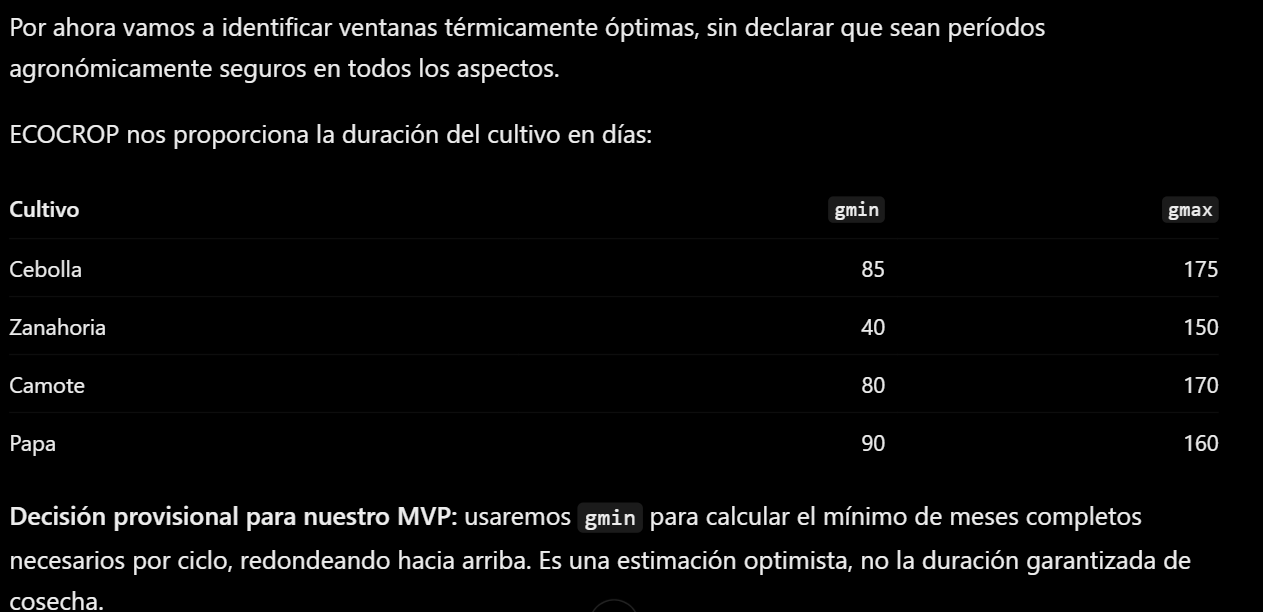

#Evaluar ventanas y capacidad de ciclos

In [ ]:

# FIELD SHIFT — GROWING WINDOWS ENGINE (V1)

import math

def find_growing_windows(point_data, crop):
    df = point_data.sort_values("month").copy()

    # Duration based on ECOCROP minimum growing days
    cycle_months = math.ceil(float(crop["gmin"]) / 30)

    # True when monthly mean temperature is optimal
    df["optimal"] = df["tmean_c"].between(
        crop["topmn"],
        crop["topmx"]
    )

    windows = []
    current_months = []

    def save_window(months):
        if not months:
            return

        duration = len(months)
        max_cycles = duration // cycle_months

        windows.append({
            "start_month": months[0],
            "end_month": months[-1],
            "window_months": duration,
            "cycle_months": cycle_months,
            "max_complete_cycles": max_cycles,
            "can_complete_cycle": max_cycles > 0
        })

    for _, row in df.iterrows():
        month = int(row["month"])

        if row["optimal"]:
            current_months.append(month)
        else:
            save_window(current_months)
            current_months = []

    save_window(current_months)

    return windows


# Test all four crops on Point 4
window_results = []

for _, crop in crop_requirements.iterrows():
    windows = find_growing_windows(
        point_data, crop
    )

    for window in windows:
        window_results.append({
            "crop": crop["crop"],
            **window
        })

windows_df = pd.DataFrame(window_results)

print("========== GROWING WINDOWS — POINT 4 ==========")
display(windows_df)


========== GROWING WINDOWS — POINT 4 ==========


,crop,start_month,end_month,window_months,cycle_months,max_complete_cycles,can_complete_cycle
0,Cebolla,1,12,12,3,4,True
1,Zanahoria,1,12,12,2,6,True
2,Camote,2,9,8,3,2,True
3,Papa,1,12,12,3,4,True


Ahora sí, pasemos de 1 punto × 4 cultivos a 192 puntos × 4 cultivos = 768 evaluaciones.

In [ ]:

# FIELD SHIFT — FULL CROP SUITABILITY EVALUATION

all_results = []

for point_id, point_months in data["monthly"].groupby("point_id"):

    # Calculate mean monthly temperature
    point_months = point_months.copy()

    point_months["tmean_c"] = (
        point_months["tmax_c"] +
        point_months["tmin_c"]
    ) / 2

    for _, crop in crop_requirements.iterrows():

        windows = find_growing_windows(
            point_months,
            crop
        )

        all_results.append({
            "point_id": int(point_id),
            "crop_id": int(crop["ecoportcode"]),
            "crop": crop["crop"],
            "scientific_name": crop["scientificname"],
            "growing_days_min": int(crop["gmin"]),
            "growing_days_max": int(crop["gmax"]),
            "windows": windows
        })

engine_results = pd.DataFrame(all_results)

print("========== FIELD SHIFT ENGINE ==========")
print("Evaluations:", len(engine_results))
print("Points:", engine_results["point_id"].nunique())
print("Crops:", engine_results["crop_id"].nunique())

print("\nWindow counts:")
display(
    engine_results.assign(
        window_count=engine_results["windows"].apply(len)
    )["window_count"].value_counts().sort_index()
)

assert len(engine_results) == 768
assert not engine_results.duplicated(
    ["point_id", "crop_id"]
).any()

print("\n✅ 768 CROP EVALUATIONS COMPLETED")


========== FIELD SHIFT ENGINE ==========
Evaluations: 768
Points: 192
Crops: 4

Window counts:


,count
window_count,
0,166
1,538
2,56
3,8



✅ 768 CROP EVALUATIONS COMPLETED


#Integrar las advertencias con los ciclos

Ahora vamos a generar exactamente lo que necesita la pestaña de anomalías de KRISS.

Para cada ciclo, añadiremos:
- Advertencias de temperatura fuera del óptimo ECOCROP.
- Observaciones de balance hídrico negativo NASA.
- Los meses específicos donde se producen.
Importante: mantendremos todas las ventanas térmicas calculadas. Un balance hídrico negativo no elimina automáticamente una ventana.

In [ ]:

# FIELD SHIFT — ENVIRONMENTAL ALERTS INTEGRATION

import copy

monthly_lookup = {
    point_id: group.set_index("month")
    for point_id, group in data["monthly"].groupby("point_id")
}

crop_lookup = {
    int(row["ecoportcode"]): row
    for _, row in crop_requirements.iterrows()
}

def generate_cycle_alerts(point_id, crop_id, start_month, end_month):
    climate = monthly_lookup[point_id]
    crop = crop_lookup[crop_id]

    alerts = []

    for month in range(start_month, end_month + 1):
        row = climate.loc[month]

        temp = (
            float(row["tmax_c"]) +
            float(row["tmin_c"])
        ) / 2

        balance = row["balance_mm"]

        # ECOCROP: temperature outside optimal range
        if not (crop["topmn"] <= temp <= crop["topmx"]):
            alerts.append({
                "month": month,
                "variable": "temperature",
                "value": round(temp, 2),
                "unit": "°C",
                "reference_min": float(crop["topmn"]),
                "reference_max": float(crop["topmx"]),
                "status": "outside_optimal",
                "source": "ECOCROP"
            })

        # NASA: descriptive climatic water balance
        if pd.notna(balance) and balance < 0:
            alerts.append({
                "month": month,
                "variable": "water_balance",
                "value": round(float(balance), 2),
                "unit": "mm",
                "status": "negative_balance",
                "source": "NASA-derived"
            })

    return alerts


enriched_results = []

for record in engine_results.to_dict("records"):

    record = copy.deepcopy(record)

    for window in record["windows"]:

        # Reconstruct complete cycles inside each window
        cycles = []

        duration = window["cycle_months"]
        start = window["start_month"]

        for index in range(window["max_complete_cycles"]):

            cycle_start = start + index * duration
            cycle_end = cycle_start + duration - 1

            alerts = generate_cycle_alerts(
                record["point_id"],
                record["crop_id"],
                cycle_start,
                cycle_end
            )

            cycles.append({
                "cycle_number": index + 1,
                "start_month": cycle_start,
                "end_month": cycle_end,
                "duration_months": duration,
                "alerts": alerts
            })

        window["cycles"] = cycles

    enriched_results.append(record)


print("========== ENRICHED ENGINE ==========")
print("Evaluations:", len(enriched_results))

total_cycles = sum(
    len(window["cycles"])
    for result in enriched_results
    for window in result["windows"]
)

total_alerts = sum(
    len(cycle["alerts"])
    for result in enriched_results
    for window in result["windows"]
    for cycle in window["cycles"]
)

print("Total complete cycles:", total_cycles)
print("Total cycle alerts:", total_alerts)

assert len(enriched_results) == 768

print("✅ CYCLE ALERTS INTEGRATED")


========== ENRICHED ENGINE ==========
Evaluations: 768
Total complete cycles: 2374
Total cycle alerts: 1150
✅ CYCLE ALERTS INTEGRATED


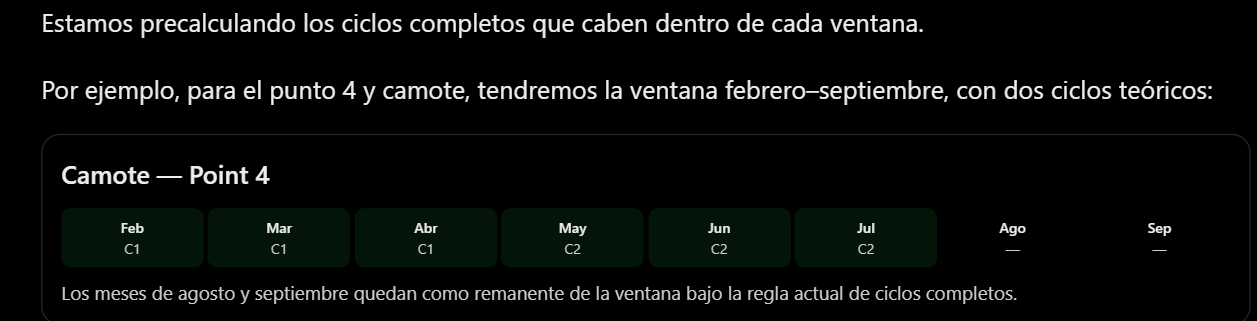

El ciclo 1 tendrá una observación de balance hídrico negativo en febrero. El ciclo 2 no tendrá advertencias según las dos reglas actuales.

#Finalizar el motor térmico

Cada combinación tendrá:
- Los doce meses evaluados contra los rangos térmicos ECOCROP.
- Las ventanas de temperatura óptima.
- Los ciclos completos estimados dentro de cada ventana.
- La clasificación mensual: favorable, caution o unfavorable.

In [ ]:

# FIELD SHIFT — THERMAL ENGINE FINALIZATION

import copy
import math

thermal_results = []

for record in enriched_results:
    point_id = record["point_id"]
    crop_id = record["crop_id"]

    crop = crop_lookup[crop_id]
    climate = monthly_lookup[point_id]

    monthly_evaluation = []

    for month in range(1, 13):
        row = climate.loc[month]

        temperature = (
            float(row["tmax_c"]) +
            float(row["tmin_c"])
        ) / 2

        if crop["topmn"] <= temperature <= crop["topmx"]:
            status = "favorable"

        elif crop["tmin"] <= temperature <= crop["tmax"]:
            status = "caution"

        else:
            status = "unfavorable"

        monthly_evaluation.append({
            "month": month,
            "temperature_c": round(temperature, 2),
            "status": status
        })

    # Preserve validated optimal windows and cycles,
    # but remove alerts from other environmental variables.
    windows = copy.deepcopy(record["windows"])

    for window in windows:
        for cycle in window["cycles"]:
            cycle["alerts"] = [
                alert
                for alert in cycle["alerts"]
                if alert["variable"] == "temperature"
            ]

    thermal_results.append({
        "point_id": point_id,
        "crop_id": crop_id,
        "crop": record["crop"],
        "scientific_name": record["scientific_name"],
        "variable": "temperature",
        "unit": "°C",
        "reference": {
            "source": "ECOCROP",
            "optimal_min": float(crop["topmn"]),
            "optimal_max": float(crop["topmx"]),
            "tolerated_min": float(crop["tmin"]),
            "tolerated_max": float(crop["tmax"])
        },
        "growing_days_min": record["growing_days_min"],
        "growing_days_max": record["growing_days_max"],
        "monthly_evaluation": monthly_evaluation,
        "windows": windows
    })

print("========== THERMAL ENGINE ==========")

print("Evaluations:", len(thermal_results))

print(
    "Monthly evaluations:",
    sum(len(r["monthly_evaluation"]) for r in thermal_results)
)

print(
    "Growing windows:",
    sum(len(r["windows"]) for r in thermal_results)
)

print(
    "Complete cycles:",
    sum(
        len(w["cycles"])
        for r in thermal_results
        for w in r["windows"]
    )
)

print(
    "Thermal cycle alerts:",
    sum(
        len(c["alerts"])
        for r in thermal_results
        for w in r["windows"]
        for c in w["cycles"]
    )
)

assert len(thermal_results) == 768
assert all(
    len(r["monthly_evaluation"]) == 12
    for r in thermal_results
)

print("\n✅ THERMAL ENGINE FINALIZED")


========== THERMAL ENGINE ==========
Evaluations: 768
Monthly evaluations: 9216
Growing windows: 674
Complete cycles: 2374
Thermal cycle alerts: 0

✅ THERMAL ENGINE FINALIZED


#Sacar los termical results para SEBAS



In [ ]:

# FIELD SHIFT — THERMAL ENGINE EXPORT
# Outputs: JSON + CSV

import pandas as pd
import numpy as np
import json
from pathlib import Path
from google.colab import files

output_dir = Path("/content/fieldshift_export")
output_dir.mkdir(exist_ok=True)

def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, np.generic):
        return json_safe(value.item())
    if value is None:
        return None
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value

# 1. EXPORT JSON — Full nested structure
json_path = output_dir / "thermal-windows.json"

with open(json_path, "w", encoding="utf-8") as f:
    json.dump(
        json_safe(thermal_results),
        f,
        ensure_ascii=False,
        indent=2,
        allow_nan=False
    )

# 2. EXPORT CSV — One row per point/crop/month
csv_rows = []

for result in thermal_results:
    for month in result["monthly_evaluation"]:
        csv_rows.append({
            "point_id": result["point_id"],
            "crop_id": result["crop_id"],
            "crop": result["crop"],
            "month": month["month"],
            "temperature_c": month["temperature_c"],
            "status": month["status"],
            "optimal_min_c": result["reference"]["optimal_min"],
            "optimal_max_c": result["reference"]["optimal_max"],
            "tolerated_min_c": result["reference"]["tolerated_min"],
            "tolerated_max_c": result["reference"]["tolerated_max"],
            "growing_days_min": result["growing_days_min"],
            "growing_days_max": result["growing_days_max"]
        })

thermal_csv = pd.DataFrame(csv_rows)

csv_path = output_dir / "thermal-windows.csv"
thermal_csv.to_csv(csv_path, index=False, encoding="utf-8-sig")

# 3. VERIFY BOTH FILES
with open(json_path, encoding="utf-8") as f:
    exported_json = json.load(f)

exported_csv = pd.read_csv(csv_path)

assert len(exported_json) == 768
assert len(exported_csv) == 9216
assert not exported_csv.duplicated(
    ["point_id", "crop_id", "month"]
).any()

print("========== EXPORT VALIDATION ==========")
print(f"JSON: {len(exported_json)} evaluations")
print(f"CSV: {len(exported_csv)} monthly records")
print(f"JSON size: {json_path.stat().st_size / 1024:.1f} KB")
print(f"CSV size: {csv_path.stat().st_size / 1024:.1f} KB")
print("✅ BOTH EXPORTS VALIDATED")

# 4. DOWNLOAD
files.download(str(json_path))
files.download(str(csv_path))


========== EXPORT VALIDATION ==========
JSON: 768 evaluations
CSV: 9216 monthly records
JSON size: 1764.6 KB
CSV size: 533.5 KB
✅ BOTH EXPORTS VALIDATED


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#Exportar ECOCROP a CSV

In [ ]:

# ECOCROP — EXPORT WITH SEPARATE COLUMNS

from google.colab import files

ecocrop_csv = crop_requirements.rename(columns={
    "ecoportcode": "crop_id",
    "scientificname": "scientific_name",
    "topmn": "optimal_temp_min_c",
    "topmx": "optimal_temp_max_c",
    "tmin": "tolerated_temp_min_c",
    "tmax": "tolerated_temp_max_c",
    "ropmn": "optimal_rain_min_mm_year",
    "ropmx": "optimal_rain_max_mm_year",
    "rmin": "tolerated_rain_min_mm_year",
    "rmax": "tolerated_rain_max_mm_year",
    "gmin": "growing_days_min",
    "gmax": "growing_days_max",
    "dra": "drainage",
    "drar": "drainage_rating"
})

ecocrop_csv.to_csv(
    "ecocrop-requirements.csv",
    index=False,
    encoding="utf-8-sig"
)

files.download("ecocrop-requirements.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#LLUVIA
Segunda variable a partir de aqui

¿Qué períodos de siembra presentan condiciones de precipitación compatibles con los requerimientos del cultivo?

#Evaluar la lluvia acumulada durante un ciclo

La metodología ECOCROP implementada en DIVA-GIS evalúa 12 posibles meses de inicio, sumando la precipitación de todo el período de crecimiento. Utiliza RMIN, ROPMN, ROPMX y RMAX para establecer la compatibilidad de lluvia.
DIVA-GIS


Para ser consistentes con el motor térmico, compararemos dos duraciones antes de fijar nuestra regla:
- MVP: ceil(GMIN / 30), como hicimos con temperatura.
- Referencia DIVA-GIS: duración representativa (GMIN + GMAX) / 2, aproximada a meses completos.

Rainfall exploration, Point 4

In [ ]:

# FIELD SHIFT — RAINFALL ENGINE
# Step 1: Explore candidate growing periods

import pandas as pd
import math

POINT_ID = 4
CROP_NAME = "Camote"

crop = crop_requirements.loc[
    crop_requirements["crop"] == CROP_NAME
].iloc[0]

climate = (
    data["monthly"]
    .loc[data["monthly"]["point_id"] == POINT_ID]
    .sort_values("month")
    .copy()
)

assert len(climate) == 12
assert climate["rain_mm"].notna().all()
assert climate["month"].tolist() == list(range(1, 13))

rain = climate.set_index("month")["rain_mm"]

# Compare two documented/explicit duration choices
duration_min = math.ceil(float(crop["gmin"]) / 30)
duration_rep = math.ceil(
    (float(crop["gmin"]) + float(crop["gmax"])) / 2 / 30
)

def evaluate_rainfall(duration_months):
    results = []

    for start in range(1, 13):

        months = [
            ((start - 1 + offset) % 12) + 1
            for offset in range(duration_months)
        ]

        rainfall_total = float(rain.loc[months].sum())

        if crop["ropmn"] <= rainfall_total <= crop["ropmx"]:
            status = "favorable"
        elif crop["rmin"] <= rainfall_total <= crop["rmax"]:
            status = "caution"
        else:
            status = "unfavorable"

        results.append({
            "start_month": start,
            "end_month": months[-1],
            "duration_months": duration_months,
            "rainfall_total_mm": round(rainfall_total, 2),
            "status": status
        })

    return pd.DataFrame(results)


print("========== CROP REQUIREMENTS ==========")
print("Crop:", CROP_NAME)
print("GMIN:", crop["gmin"], "days")
print("GMAX:", crop["gmax"], "days")
print("MVP duration:", duration_min, "months")
print("Representative duration:", duration_rep, "months")

print("\n========== ECOCROP RAINFALL LIMITS ==========")
print("Tolerated minimum:", crop["rmin"], "mm")
print("Optimal minimum:", crop["ropmn"], "mm")
print("Optimal maximum:", crop["ropmx"], "mm")
print("Tolerated maximum:", crop["rmax"], "mm")

print("\n========== GMIN-BASED RESULTS ==========")
rain_min_results = evaluate_rainfall(duration_min)
display(rain_min_results)

print("\n========== REPRESENTATIVE-DURATION RESULTS ==========")
rain_rep_results = evaluate_rainfall(duration_rep)
display(rain_rep_results)


========== CROP REQUIREMENTS ==========
Crop: Camote
GMIN: 80 days
GMAX: 170 days
MVP duration: 3 months
Representative duration: 5 months

========== ECOCROP RAINFALL LIMITS ==========
Tolerated minimum: 350 mm
Optimal minimum: 750 mm
Optimal maximum: 2000 mm
Tolerated maximum: 5000 mm

========== GMIN-BASED RESULTS ==========


,start_month,end_month,duration_months,rainfall_total_mm,status
0,1,3,3,261.95,unfavorable
1,2,4,3,419.56,caution
2,3,5,3,699.46,caution
3,4,6,3,1017.14,favorable
4,5,7,3,1141.75,favorable
5,6,8,3,1090.46,favorable
6,7,9,3,990.46,favorable
7,8,10,3,1008.34,favorable
8,9,11,3,1066.25,favorable
9,10,12,3,912.79,favorable



========== REPRESENTATIVE-DURATION RESULTS ==========


,start_month,end_month,duration_months,rainfall_total_mm,status
0,1,5,5,844.49,favorable
1,2,6,5,1194.58,favorable
2,3,7,5,1500.79,favorable
3,4,8,5,1673.00,favorable
4,5,9,5,1765.48,favorable
5,6,10,5,1809.67,favorable
6,7,11,5,1722.11,favorable
7,8,12,5,1536.52,favorable
8,9,1,5,1331.90,favorable
9,10,2,5,1057.82,favorable


#Validar primero lluvia anual



In [ ]:

# FIELD SHIFT — ANNUAL RAINFALL VALIDATION
# Direct comparison: NASA mm/year vs ECOCROP mm/year

POINT_ID = 4

annual_point = data["annual_normal"].loc[
    data["annual_normal"]["point_id"] == POINT_ID
]

assert len(annual_point) == 1

annual_rainfall = float(
    annual_point["rain_mm"].iloc[0]
)

annual_results = []

for _, crop in crop_requirements.iterrows():

    if crop["ropmn"] <= annual_rainfall <= crop["ropmx"]:
        status = "favorable"

    elif crop["rmin"] <= annual_rainfall <= crop["rmax"]:
        status = "caution"

    else:
        status = "unfavorable"

    annual_results.append({
        "point_id": POINT_ID,
        "crop": crop["crop"],
        "annual_rain_mm": round(annual_rainfall, 2),
        "optimal_min_mm_year": crop["ropmn"],
        "optimal_max_mm_year": crop["ropmx"],
        "tolerated_min_mm_year": crop["rmin"],
        "tolerated_max_mm_year": crop["rmax"],
        "status": status
    })

annual_rainfall_validation = pd.DataFrame(annual_results)

print("========== ANNUAL RAINFALL ==========")
display(annual_rainfall_validation)


========== ANNUAL RAINFALL ==========


,point_id,crop,annual_rain_mm,optimal_min_mm_year,optimal_max_mm_year,tolerated_min_mm_year,tolerated_max_mm_year,status
0,4,Cebolla,3182.34,350,600,300,2800,unfavorable
1,4,Zanahoria,3182.34,600,1200,400,4000,caution
2,4,Camote,3182.34,750,2000,350,5000,caution
3,4,Papa,3182.34,500,800,250,2000,unfavorable


#Evaluar precipitación anual para los 192 puntos

In [ ]:

# FIELD SHIFT — ANNUAL RAINFALL ENGINE
# 192 points × 4 crops

annual_rainfall_results = []

for _, point in data["annual_normal"].iterrows():

    point_id = int(point["point_id"])
    annual_rain = float(point["rain_mm"])

    for _, crop in crop_requirements.iterrows():

        optimal_min = float(crop["ropmn"])
        optimal_max = float(crop["ropmx"])
        tolerated_min = float(crop["rmin"])
        tolerated_max = float(crop["rmax"])

        if optimal_min <= annual_rain <= optimal_max:
            status = "favorable"

        elif tolerated_min <= annual_rain <= tolerated_max:
            status = "caution"

        else:
            status = "unfavorable"

        annual_rainfall_results.append({
            "point_id": point_id,
            "crop_id": int(crop["ecoportcode"]),
            "crop": crop["crop"],
            "annual_rain_mm": round(annual_rain, 2),
            "optimal_min_mm_year": optimal_min,
            "optimal_max_mm_year": optimal_max,
            "tolerated_min_mm_year": tolerated_min,
            "tolerated_max_mm_year": tolerated_max,
            "status": status
        })

annual_rainfall_df = pd.DataFrame(
    annual_rainfall_results
)

# Validation
assert len(annual_rainfall_df) == 768

assert not annual_rainfall_df.duplicated(
    ["point_id", "crop_id"]
).any()

print("========== ANNUAL RAINFALL ENGINE ==========")
print("Evaluations:", len(annual_rainfall_df))
print("Points:", annual_rainfall_df["point_id"].nunique())
print("Crops:", annual_rainfall_df["crop_id"].nunique())

print("\n========== SUITABILITY DISTRIBUTION ==========")

display(
    pd.crosstab(
        annual_rainfall_df["crop"],
        annual_rainfall_df["status"]
    )
)

print("\n✅ ANNUAL RAINFALL ENGINE VALIDATED")


========== ANNUAL RAINFALL ENGINE ==========
Evaluations: 768
Points: 192
Crops: 4

========== SUITABILITY DISTRIBUTION ==========


status,caution,unfavorable
crop,,
Camote,192,0
Cebolla,0,192
Papa,0,192
Zanahoria,192,0



✅ ANNUAL RAINFALL ENGINE VALIDATED


In [ ]:

# FIELD SHIFT — ANNUAL RAINFALL DIAGNOSTIC

annual = data["annual_normal"].copy()

print("========== ANNUAL RAINFALL DIAGNOSTIC ==========")

print("Points:", annual["point_id"].nunique())
print("Minimum:", round(annual["rain_mm"].min(), 2), "mm/year")
print("Maximum:", round(annual["rain_mm"].max(), 2), "mm/year")
print("Mean:", round(annual["rain_mm"].mean(), 2), "mm/year")
print("Standard deviation:",
      round(annual["rain_mm"].std(), 2), "mm/year")

print("\n========== RAINFALL DISTRIBUTION ==========")

display(
    annual["rain_mm"].describe().to_frame(
        "annual_rain_mm"
    )
)

print("\n========== DRIEST 5 POINTS ==========")

display(
    annual[
        ["point_id", "rain_mm"]
    ].nsmallest(5, "rain_mm")
)

print("\n========== WETTEST 5 POINTS ==========")

display(
    annual[
        ["point_id", "rain_mm"]
    ].nlargest(5, "rain_mm")
)

print("\n========== STATUS VALIDATION ==========")

assert annual["rain_mm"].notna().all()
assert (annual["rain_mm"] >= 0).all()

print("✅ ANNUAL RAINFALL DIAGNOSTIC COMPLETED")


========== ANNUAL RAINFALL DIAGNOSTIC ==========
Points: 192
Minimum: 2979.17 mm/year
Maximum: 3562.29 mm/year
Mean: 3137.65 mm/year
Standard deviation: 129.59 mm/year

========== RAINFALL DISTRIBUTION ==========


,annual_rain_mm
count,192.000000
mean,3137.646875
std,129.593873
min,2979.170000
25%,3054.930000
50%,3118.635000
75%,3182.340000
max,3562.290000



========== DRIEST 5 POINTS ==========


,point_id,rain_mm
96,97,2979.17
97,98,2979.17
112,113,2979.17
113,114,2979.17
128,129,2979.17



========== WETTEST 5 POINTS ==========


,point_id,rain_mm
0,1,3562.29
1,2,3562.29
16,17,3562.29
17,18,3562.29
32,33,3562.29



========== STATUS VALIDATION ==========
✅ ANNUAL RAINFALL DIAGNOSTIC COMPLETED


#Rainfall Seasonal Engine

Construir nuestras ventanas optimas de cultivo para la variable lluvia

In [ ]:

# FIELD SHIFT — SEASONAL RAINFALL ENGINE
# 192 points × 4 crops × 12 possible planting starts

import math
import pandas as pd

seasonal_rainfall_results = []

for point_id, climate in data["monthly"].groupby("point_id"):

    climate = climate.sort_values("month").copy()

    assert climate["month"].tolist() == list(range(1, 13))
    assert climate["rain_mm"].notna().all()

    monthly_rain = climate.set_index("month")["rain_mm"]

    for _, crop in crop_requirements.iterrows():

        # Representative cycle duration
        duration_days = (
            float(crop["gmin"]) + float(crop["gmax"])
        ) / 2

        duration_months = math.ceil(duration_days / 30)

        candidates = []

        for start in range(1, 13):

            # Circular months: supports Dec -> Jan
            months = [
                ((start - 1 + offset) % 12) + 1
                for offset in range(duration_months)
            ]

            accumulated_rain = float(
                monthly_rain.loc[months].sum()
            )

            if crop["ropmn"] <= accumulated_rain <= crop["ropmx"]:
                status = "favorable"

            elif crop["rmin"] <= accumulated_rain <= crop["rmax"]:
                status = "caution"

            else:
                status = "unfavorable"

            candidates.append({
                "start_month": start,
                "end_month": months[-1],
                "months": months,
                "duration_months": duration_months,
                "rain_total_mm": round(accumulated_rain, 2),
                "status": status
            })

        seasonal_rainfall_results.append({
            "point_id": int(point_id),
            "crop_id": int(crop["ecoportcode"]),
            "crop": crop["crop"],
            "variable": "rainfall",
            "method": "growing_period_accumulation",
            "duration_days": duration_days,
            "duration_months": duration_months,
            "candidates": candidates
        })


# Validate
assert len(seasonal_rainfall_results) == 768

assert all(
    len(r["candidates"]) == 12
    for r in seasonal_rainfall_results
)

assert len({
    (r["point_id"], r["crop_id"])
    for r in seasonal_rainfall_results
}) == 768

# Analyze classifications
seasonal_summary = pd.DataFrame([
    {
        "crop": result["crop"],
        "status": candidate["status"]
    }
    for result in seasonal_rainfall_results
    for candidate in result["candidates"]
])

print("========== SEASONAL RAINFALL ENGINE ==========")
print("Evaluations:", len(seasonal_rainfall_results))
print("Planting starts:", len(seasonal_summary))

print("\n========== STATUS DISTRIBUTION ==========")

display(
    pd.crosstab(
        seasonal_summary["crop"],
        seasonal_summary["status"]
    )
)

print("\n✅ SEASONAL RAINFALL ENGINE COMPLETED")


========== SEASONAL RAINFALL ENGINE ==========
Evaluations: 768
Planting starts: 9216

========== STATUS DISTRIBUTION ==========


status,caution,favorable,unfavorable
crop,,,
Camote,264,2040,0
Cebolla,2280,24,0
Papa,1968,300,36
Zanahoria,1344,924,36



✅ SEASONAL RAINFALL ENGINE COMPLETED


PASO 6 — Construir las ventanas de inicio de siembra
Ya tenemos las evaluaciones. Ahora necesitamos traducirlas a ventanas que SEBAS pueda pintar en el calendario.

Por ejemplo, si abril, mayo y junio son fechas de inicio favorables para camote, tendremos una ventana de inicio abril–junio.

No significa que el cultivo deba terminar en junio: cada fecha de inicio tiene su propia fecha estimada de finalización.

In [ ]:

# FIELD SHIFT — RAINFALL PLANTING WINDOWS

def build_rainfall_windows(candidates):
    """
    Group consecutive favorable planting-start months.
    Supports circular calendar: December -> January.
    """

    favorable = {
        int(c["start_month"])
        for c in candidates
        if c["status"] == "favorable"
    }

    if not favorable:
        return []

    # All months favorable = one full-year window
    if len(favorable) == 12:
        groups = [list(range(1, 13))]

    else:
        # Start a group after a non-favorable month
        first = next(
            m for m in range(1, 13)
            if m not in favorable
        )

        groups = []
        current = []

        for offset in range(1, 13):
            month = ((first - 1 + offset) % 12) + 1

            if month in favorable:
                current.append(month)
            elif current:
                groups.append(current)
                current = []

        if current:
            groups.append(current)

    windows = []

    for i, months in enumerate(groups, start=1):
        windows.append({
            "window_id": i,
            "start_month": months[0],
            "end_month": months[-1],
            "planting_months": months,
            "window_months": len(months),
            "status": "favorable",
            "candidates": [
                c for c in candidates
                if int(c["start_month"]) in months
            ]
        })

    return windows


# Add planting windows to all 768 evaluations
for result in seasonal_rainfall_results:
    result["windows"] = build_rainfall_windows(
        result["candidates"]
    )


# Validate groups and their underlying candidates
for result in seasonal_rainfall_results:

    expected = {
        c["start_month"]
        for c in result["candidates"]
        if c["status"] == "favorable"
    }

    grouped = [
        month
        for window in result["windows"]
        for month in window["planting_months"]
    ]

    assert len(grouped) == len(set(grouped))
    assert set(grouped) == expected


print("========== RAINFALL WINDOWS ==========")

print("Evaluations:", len(seasonal_rainfall_results))

print(
    "Total windows:",
    sum(
        len(r["windows"])
        for r in seasonal_rainfall_results
    )
)

print("\n========== WINDOWS BY CROP ==========")

summary = pd.DataFrame([
    {
        "crop": r["crop"],
        "window_count": len(r["windows"])
    }
    for r in seasonal_rainfall_results
])

display(
    summary.groupby("crop")["window_count"]
    .agg(["sum", "mean", "max"])
)

print("\n========== POINT 4 — CAMOTE ==========")

example = next(
    r for r in seasonal_rainfall_results
    if r["point_id"] == 4
    and r["crop"] == "Camote"
)

display(pd.DataFrame([
    {
        "start_month": w["start_month"],
        "end_month": w["end_month"],
        "planting_months": w["planting_months"],
        "window_months": w["window_months"]
    }
    for w in example["windows"]
]))

print("\n✅ RAINFALL WINDOWS VALIDATED")


========== RAINFALL WINDOWS ==========
Evaluations: 768
Total windows: 900

========== WINDOWS BY CROP ==========


,sum,mean,max
crop,,,
Camote,204,1.0625,2
Cebolla,24,0.1250,1
Papa,204,1.0625,2
Zanahoria,468,2.4375,3



========== POINT 4 — CAMOTE ==========


,start_month,end_month,planting_months,window_months
0,1,11,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]",11



✅ RAINFALL WINDOWS VALIDATED


#Exportar rainfall engine

In [ ]:

# FIELD SHIFT — RAINFALL ENGINE EXPORT
# JSON + CSV (seasonal) + CSV (annual)

import pandas as pd
import numpy as np
import json
from pathlib import Path
from google.colab import files

output_dir = Path("/content/fieldshift_export")
output_dir.mkdir(exist_ok=True)

def json_safe(value):
    if isinstance(value, dict):
        return {
            str(k): json_safe(v)
            for k, v in value.items()
        }
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, np.generic):
        return json_safe(value.item())
    if value is None:
        return None
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value

# 1. JSON — Full rainfall engine, including windows
json_path = output_dir / "rainfall-windows.json"

with open(json_path, "w", encoding="utf-8") as f:
    json.dump(
        json_safe(seasonal_rainfall_results),
        f,
        ensure_ascii=False,
        indent=2,
        allow_nan=False
    )

# 2. CSV — One record per planting-start evaluation
csv_rows = []

for result in seasonal_rainfall_results:
    for candidate in result["candidates"]:
        csv_rows.append({
            "point_id": result["point_id"],
            "crop_id": result["crop_id"],
            "crop": result["crop"],
            "start_month": candidate["start_month"],
            "end_month": candidate["end_month"],
            "duration_months": candidate["duration_months"],
            "rain_total_mm": candidate["rain_total_mm"],
            "status": candidate["status"],
            "duration_days": result["duration_days"]
        })

rainfall_csv = pd.DataFrame(csv_rows)

csv_path = output_dir / "rainfall-windows.csv"
rainfall_csv.to_csv(
    csv_path,
    index=False,
    encoding="utf-8-sig"
)

# 3. CSV — Annual ECOCROP comparison
annual_path = output_dir / "annual-rainfall.csv"

annual_rainfall_df.to_csv(
    annual_path,
    index=False,
    encoding="utf-8-sig"
)

# 4. Validate exports
with open(json_path, encoding="utf-8") as f:
    loaded_json = json.load(f)

assert len(loaded_json) == 768
assert len(rainfall_csv) == 9216
assert len(annual_rainfall_df) == 768

assert not rainfall_csv.duplicated(
    ["point_id", "crop_id", "start_month"]
).any()

print("========== RAINFALL EXPORT ==========")
for path in [json_path, csv_path, annual_path]:
    print(
        f"✅ {path.name}: "
        f"{path.stat().st_size / 1024:.1f} KB"
    )

print("\n✅ ALL RAINFALL EXPORTS VALIDATED")

# 5. Download
files.download(str(json_path))
files.download(str(csv_path))
files.download(str(annual_path))


========== RAINFALL EXPORT ==========
✅ rainfall-windows.json: 3689.0 KB
✅ rainfall-windows.csv: 396.1 KB
✅ annual-rainfall.csv: 44.3 KB

✅ ALL RAINFALL EXPORTS VALIDATED


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#HUMEDAD A PARTIR DE AQUI

In [ ]:

# FIELD SHIFT — SOIL WETNESS EXPLORATION

import pandas as pd

monthly = data["monthly"].copy()

print("========== SOIL WETNESS DATA QUALITY ==========")

print("Records:", len(monthly))
print("Points:", monthly["point_id"].nunique())
print("Missing:", monthly["soil_wetness"].isna().sum())

print("Below 0:", (monthly["soil_wetness"] < 0).sum())
print("Above 1:", (monthly["soil_wetness"] > 1).sum())

print("\n========== DISTRIBUTION ==========")

display(
    monthly["soil_wetness"].describe()
)

print("\n========== POINT 4 ==========")

display(
    monthly.loc[
        monthly["point_id"] == 4,
        ["month", "soil_wetness"]
    ].sort_values("month")
)

print("\n========== MONTHLY REGIONAL PATTERN ==========")

display(
    monthly.groupby("month")["soil_wetness"]
    .agg(["min", "mean", "max"])
    .round(3)
)

assert monthly["soil_wetness"].between(0, 1).all()

print("\n✅ SOIL WETNESS EXPLORATION COMPLETED")


========== SOIL WETNESS DATA QUALITY ==========
Records: 2304
Points: 192
Missing: 0
Below 0: 0
Above 1: 0

========== DISTRIBUTION ==========


,soil_wetness
count,2304.000000
mean,0.870052
std,0.119663
min,0.490000
25%,0.760000
50%,0.940000
75%,0.970000
max,0.990000



========== POINT 4 ==========


,month,soil_wetness
36,1,0.86
37,2,0.74
38,3,0.68
39,4,0.71
40,5,0.81
41,6,0.94
42,7,0.97
43,8,0.97
44,9,0.98
45,10,0.99



========== MONTHLY REGIONAL PATTERN ==========


,min,mean,max
month,,,
1,0.72,0.852,0.87
2,0.57,0.732,0.76
3,0.49,0.665,0.69
4,0.50,0.695,0.72
5,0.62,0.788,0.81
6,0.81,0.928,0.94
7,0.87,0.959,0.97
8,0.88,0.960,0.97
9,0.90,0.971,0.98



✅ SOIL WETNESS EXPLORATION COMPLETED


#Clasificar la humedad de los 192 puntos

In [ ]:

# FIELD SHIFT — SOIL WETNESS ENGINE
# Relative seasonal classification by geographic point

import pandas as pd
import numpy as np

wetness_data = data["monthly"][
    ["point_id", "month", "soil_wetness"]
].copy()

# Calculate local median for each geographic point
wetness_data["local_median"] = (
    wetness_data.groupby("point_id")["soil_wetness"]
    .transform("median")
)

def classify_wetness(row):
    if row["soil_wetness"] > row["local_median"]:
        return "relatively_wetter"

    if row["soil_wetness"] < row["local_median"]:
        return "relatively_drier"

    return "at_median"

wetness_data["status"] = wetness_data.apply(
    classify_wetness,
    axis=1
)

# Validation
assert len(wetness_data) == 2304
assert wetness_data["soil_wetness"].notna().all()
assert wetness_data["local_median"].notna().all()

assert not wetness_data.duplicated(
    ["point_id", "month"]
).any()

print("========== SOIL WETNESS ENGINE ==========")
print("Records:", len(wetness_data))
print("Points:", wetness_data["point_id"].nunique())

print("\n========== STATUS DISTRIBUTION ==========")
display(wetness_data["status"].value_counts())

print("\n========== POINT 4 ==========")
display(
    wetness_data[
        wetness_data["point_id"] == 4
    ].sort_values("month")
)

print("\n✅ SOIL WETNESS CLASSIFICATION VALIDATED")


========== SOIL WETNESS ENGINE ==========
Records: 2304
Points: 192

========== STATUS DISTRIBUTION ==========


,count
status,
relatively_drier,1068
relatively_wetter,1068
at_median,168



========== POINT 4 ==========


,point_id,month,soil_wetness,local_median,status
36,4,1,0.86,0.94,relatively_drier
37,4,2,0.74,0.94,relatively_drier
38,4,3,0.68,0.94,relatively_drier
39,4,4,0.71,0.94,relatively_drier
40,4,5,0.81,0.94,relatively_drier
41,4,6,0.94,0.94,at_median
42,4,7,0.97,0.94,relatively_wetter
43,4,8,0.97,0.94,relatively_wetter
44,4,9,0.98,0.94,relatively_wetter
45,4,10,0.99,0.94,relatively_wetter



✅ SOIL WETNESS CLASSIFICATION VALIDATED


#Construir ventanas independientes de humedad

In [ ]:

# FIELD SHIFT — SOIL WETNESS WINDOWS
# Group consecutive months by relative wetness status

def group_circular_months(months):
    """Group consecutive calendar months, including Dec-Jan."""
    selected = set(int(m) for m in months)

    if not selected:
        return []

    if len(selected) == 12:
        return [list(range(1, 13))]

    # Find a month outside the selected set
    anchor = next(
        m for m in range(1, 13)
        if m not in selected
    )

    groups = []
    current = []

    for step in range(1, 13):
        month = ((anchor - 1 + step) % 12) + 1

        if month in selected:
            current.append(month)
        elif current:
            groups.append(current)
            current = []

    if current:
        groups.append(current)

    return groups


wetness_results = []

for point_id, group in wetness_data.groupby("point_id"):

    group = group.sort_values("month")
    local_median = float(group["local_median"].iloc[0])

    monthly_evaluation = [
        {
            "month": int(row["month"]),
            "soil_wetness": float(row["soil_wetness"]),
            "status": row["status"]
        }
        for _, row in group.iterrows()
    ]

    windows = []

    for status in ["relatively_drier", "relatively_wetter"]:

        months = group.loc[
            group["status"] == status,
            "month"
        ].tolist()

        grouped = group_circular_months(months)

        for months_group in grouped:
            windows.append({
                "status": status,
                "start_month": months_group[0],
                "end_month": months_group[-1],
                "months": months_group,
                "duration_months": len(months_group)
            })

    wetness_results.append({
        "point_id": int(point_id),
        "variable": "soil_wetness",
        "unit": "index_0_1",
        "source": "NASA POWER GWETROOT",
        "method": "local_monthly_median",
        "local_median": local_median,
        "monthly_evaluation": monthly_evaluation,
        "windows": windows
    })


# Validate
assert len(wetness_results) == 192

assert all(
    len(r["monthly_evaluation"]) == 12
    for r in wetness_results
)

for result in wetness_results:
    for status in ["relatively_drier", "relatively_wetter"]:

        expected = {
            m["month"]
            for m in result["monthly_evaluation"]
            if m["status"] == status
        }

        actual = [
            m
            for w in result["windows"]
            if w["status"] == status
            for m in w["months"]
        ]

        assert set(actual) == expected
        assert len(actual) == len(set(actual))


print("========== SOIL WETNESS WINDOWS ==========")
print("Points:", len(wetness_results))

print(
    "Total windows:",
    sum(len(r["windows"]) for r in wetness_results)
)

print("\n========== WINDOWS BY STATUS ==========")

window_summary = pd.DataFrame([
    {
        "status": window["status"],
        "duration_months": window["duration_months"]
    }
    for result in wetness_results
    for window in result["windows"]
])

display(
    window_summary.groupby("status")["duration_months"]
    .agg(["count", "mean", "max"])
)

print("\n========== POINT 4 WINDOWS ==========")

example = next(
    r for r in wetness_results
    if r["point_id"] == 4
)

display(pd.DataFrame(example["windows"]))

print("\n✅ SOIL WETNESS WINDOWS VALIDATED")


========== SOIL WETNESS WINDOWS ==========
Points: 192
Total windows: 384

========== WINDOWS BY STATUS ==========


,count,mean,max
status,,,
relatively_drier,192,5.5625,6
relatively_wetter,192,5.5625,6



========== POINT 4 WINDOWS ==========


,status,start_month,end_month,months,duration_months
0,relatively_drier,1,5,"[1, 2, 3, 4, 5]",5
1,relatively_wetter,7,11,"[7, 8, 9, 10, 11]",5



✅ SOIL WETNESS WINDOWS VALIDATED


#Generar las ventanas de humedad por cultivo

In [ ]:

# FIELD SHIFT — CROP-AWARE SOIL WETNESS ENGINE

import math
import pandas as pd
import numpy as np

soil_wetness_results = []

for point_id, climate in data["monthly"].groupby("point_id"):

    climate = climate.sort_values("month").copy()

    assert climate["month"].tolist() == list(range(1, 13))
    assert climate["soil_wetness"].notna().all()

    wetness = climate.set_index("month")["soil_wetness"]
    local_median = float(wetness.median())

    for _, crop in crop_requirements.iterrows():

        duration_days = (
            float(crop["gmin"]) + float(crop["gmax"])
        ) / 2

        duration_months = math.ceil(duration_days / 30)

        candidates = []

        for start in range(1, 13):

            months = [
                ((start - 1 + i) % 12) + 1
                for i in range(duration_months)
            ]

            cycle_values = wetness.loc[months]
            cycle_mean = float(cycle_values.mean())

            # Tiny tolerance avoids floating-point artifacts
            if np.isclose(cycle_mean, local_median, atol=1e-9):
                status = "at_median"
            elif cycle_mean < local_median:
                status = "relatively_drier"
            else:
                status = "relatively_wetter"

            candidates.append({
                "start_month": start,
                "end_month": months[-1],
                "months": months,
                "duration_months": duration_months,
                "mean_soil_wetness": round(cycle_mean, 4),
                "local_median": round(local_median, 4),
                "status": status
            })

        # Group consecutive planting starts by status
        windows = []

        for status in ["relatively_drier", "relatively_wetter"]:

            starts = [
                c["start_month"]
                for c in candidates
                if c["status"] == status
            ]

            for group in group_circular_months(starts):
                windows.append({
                    "status": status,
                    "start_month": group[0],
                    "end_month": group[-1],
                    "planting_months": group,
                    "window_months": len(group)
                })

        soil_wetness_results.append({
            "point_id": int(point_id),
            "crop_id": int(crop["ecoportcode"]),
            "crop": crop["crop"],
            "variable": "soil_wetness",
            "source": "NASA POWER GWETROOT",
            "method": "cycle_mean_vs_local_median",
            "unit": "relative_saturation_0_1",
            "duration_days": duration_days,
            "duration_months": duration_months,
            "local_median": round(local_median, 4),
            "candidates": candidates,
            "windows": windows
        })

# VALIDATION

assert len(soil_wetness_results) == 768
assert len({
    (r["point_id"], r["crop_id"])
    for r in soil_wetness_results
}) == 768

assert all(
    len(r["candidates"]) == 12
    for r in soil_wetness_results
)

for result in soil_wetness_results:
    for status in ["relatively_drier", "relatively_wetter"]:
        expected = {
            c["start_month"]
            for c in result["candidates"]
            if c["status"] == status
        }
        actual = [
            month
            for w in result["windows"]
            if w["status"] == status
            for month in w["planting_months"]
        ]
        assert set(actual) == expected
        assert len(actual) == len(set(actual))

print("========== SOIL WETNESS ENGINE ==========")
print("Evaluations:", len(soil_wetness_results))
print("Planting starts:", sum(
    len(r["candidates"]) for r in soil_wetness_results
))
print("Total windows:", sum(
    len(r["windows"]) for r in soil_wetness_results
))

summary = pd.DataFrame([
    {"crop": r["crop"], "status": c["status"]}
    for r in soil_wetness_results
    for c in r["candidates"]
])

print("\n========== STATUS DISTRIBUTION ==========")
display(pd.crosstab(summary["crop"], summary["status"]))

print("\n========== POINT 4 — ALL CROPS ==========")
display(pd.DataFrame([
    {
        "crop": r["crop"],
        "duration_months": r["duration_months"],
        "windows": [
            (w["status"], w["planting_months"])
            for w in r["windows"]
        ]
    }
    for r in soil_wetness_results
    if r["point_id"] == 4
]))

print("\n✅ CROP-AWARE SOIL WETNESS ENGINE VALIDATED")


========== SOIL WETNESS ENGINE ==========
Evaluations: 768
Planting starts: 9216
Total windows: 1536

========== STATUS DISTRIBUTION ==========


status,relatively_drier,relatively_wetter
crop,,
Camote,1524,780
Cebolla,1524,780
Papa,1524,780
Zanahoria,1356,948



========== POINT 4 — ALL CROPS ==========


,crop,duration_months,windows
0,Cebolla,5,"[(relatively_drier, [10, 11, 12, 1, 2, 3, 4, 5..."
1,Zanahoria,4,"[(relatively_drier, [11, 12, 1, 2, 3, 4, 5]), ..."
2,Camote,5,"[(relatively_drier, [10, 11, 12, 1, 2, 3, 4, 5..."
3,Papa,5,"[(relatively_drier, [10, 11, 12, 1, 2, 3, 4, 5..."



✅ CROP-AWARE SOIL WETNESS ENGINE VALIDATED
